In [2]:
"""
cell 1 : thiết lập seed tái lập (42) và định hướng path project
- matplotlib / searborn 
- input : môi trường python + các thư viện đồ họa
- output expected:  thông báo ok, khởi tạo thư mục reports/figures/ để sẵn sàng lưu biểu đồ cho bài báo latex
"""

import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

#1, Path of project
NOTEBOOK_DIR = Path.cwd()
BASE_DIR = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))
PROCESSED_DATA_PATH = BASE_DIR / "data" / "processed" / "train.parquet"
FIGURES_DIR = BASE_DIR / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

#2. academic publication style
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.titlesize": 13,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.linestyle": "--"
})

PALETTE = {
    "negative": "#D9534F",
    "neutral": "#8E9AA8",
    "positive": "#2E7D32"
}

print(f"Thư mục gốc: {BASE_DIR}")
print(f"Đường dẫn dữ liệu Train: {PROCESSED_DATA_PATH}")
print(f"Thư mục lưu biểu đồ báo cáo: {FIGURES_DIR}")

Thư mục gốc: d:\Vscode-luyện code\TMG
Đường dẫn dữ liệu Train: d:\Vscode-luyện code\TMG\data\processed\train.parquet
Thư mục lưu biểu đồ báo cáo: d:\Vscode-luyện code\TMG\reports\figures


In [3]:
from numpy.random import sample
"""
Cell2 : data ingestion & data leakage guardrail
- chỉ nạp train.parquet vào EDA 
- kiểm định Data integrity Audit:
    1. kiểm tra shape
    2. ra soát NaN
    3, rà soát duplicate
    4. hiển thị mẫu đại diện từng class dể có định tính ban dầu
- input: 'data/processed/train.parquet'
- output : Table thể hiện trạng thái tài liệu (.. dòng, .. missing value, .. duplicate... nếu có)
"""

df_train  =  pd.read_parquet(PROCESSED_DATA_PATH)

#1. kiểm tra shape và datatype
print("="*80)
print(f"- Number of Samples : {len(df_train):,}")
print(f"- Number of Features : {df_train.shape[1]}")
print(f"- List attributes & Datatype:")
for col, dtype in df_train.dtypes.items():
    print(f" + {col:<12}: {dtype}")

#2. missing value check
missing_counts = df_train.isnull().sum()
empty_strings = (df_train['sentence'].str.strip()=="").sum()
print(f"\n- Numbers of NaN Values : {missing_counts.sum()}")
print(f"- Numbers of null String  : {empty_strings}")

#3. Duplicate checking
duplicate_sentences = df_train.duplicated(subset=["sentence"]).sum()
print(f"- Số câu trùng lặp nội dung văn bản: {duplicate_sentences} ({duplicate_sentences/len(df_train)*100:.2f}%)")

#4. Show heads
print(f"\n -- qualitative examples--")
for label in ["positive", "neutral", "negative"]:
    sample_text = df_train[df_train["label_name"] == label]["sentence"].iloc[0]
    print(f"[{label.upper()}] : \n \"{sample_text}\"\n")

- Number of Samples : 2,417
- Number of Features : 4
- List attributes & Datatype:
 + sentence    : str
 + label_name  : str
 + label       : int64
 + id          : int64

- Numbers of NaN Values : 0
- Numbers of null String  : 0
- Số câu trùng lặp nội dung văn bản: 3 (0.12%)

 -- qualitative examples--
[POSITIVE] : 
 "Furthermore , efficiency improvement measures initiated earlier are now bearing fruit , '' CEO Jan Lang said ."

[NEUTRAL] : 
 "Also , a seven-year historic analysis is provided for these markets ."

[NEGATIVE] : 
 "Profit for the period totalled EUR 1.1 mn , down from EUR 1.6 mn in the third quarter of 2008 ."



Report class imbalance audit
- Negative :   294 samples (12.16% | Weights W_c : 2.7404)
- Neutral  :  1502 samples (62.14% | Weights W_c : 0.5364)
- Positive :   621 samples (25.69% | Weights W_c : 1.2974)

=> Tỷ số mất cân bằng (Imbalance Ratio): 5.11 : 1

 Đã xuất biểu đồ học thuật tại:
    + PDF (Vector): d:\Vscode-luyện code\TMG\reports\figures\class_distribution.pdf
    + PNG (Preview): d:\Vscode-luyện code\TMG\reports\figures\class_distribution.png


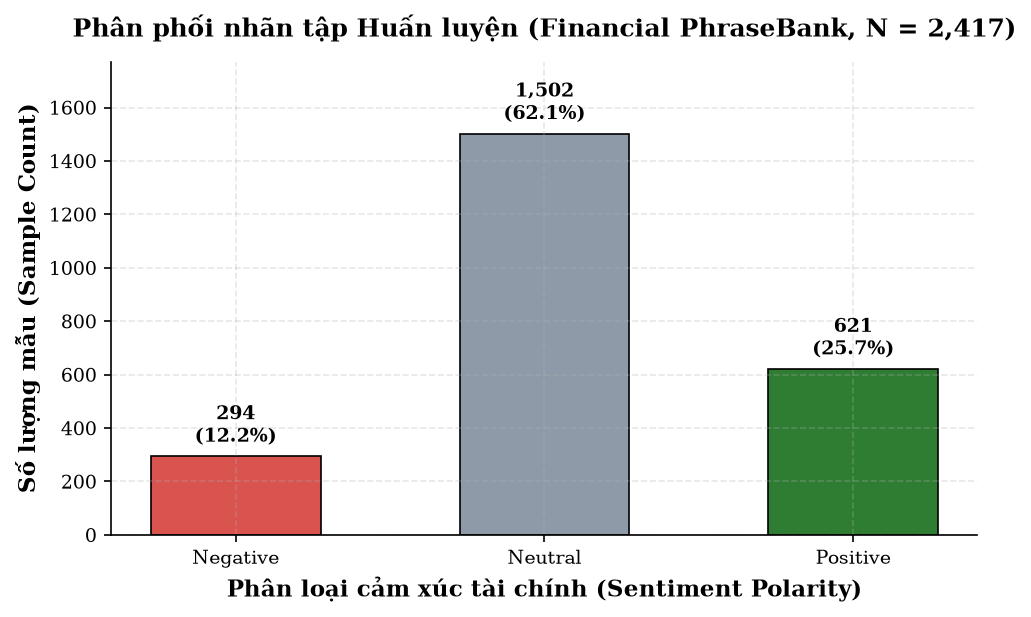

In [4]:
"""
cell 3 : class imbalance audit & Scientific visualiuzation 
- định lượng độ lẹch lớp (tỉ lệ% và ratio N_majority / N_minority)
- class weights = theo công thức w_c = N / (C . N_c) (được đưa thẳng vào hàm Cross-Entropy Loss khi fine-tune FinBERT ở pharse 3)
- vễ barchat chuẩn iEEE, tự động lưu file vector class_distribution.pdf (cho file latex) và file ảnh class_distribution.png

-input  : cột label_name của 'df_train'
-output : 
    1. bảng số liệu chi tiết
    2. Tệp biểu đồ reports/figures/class_distribution.pdf và class_distribution.png.
    3. biểu đồ sắc nét thể hiện trong notebooks
"""

import numpy as np 

#1. thống kê số lượng và tỷ lệ phân phối
class_counts = df_train["label_name"].value_counts()
class_order = ["negative", "neutral" ,"positive"]
class_counts = class_counts.reindex(class_order)
total_samples = len(df_train)
class_percentages = (class_counts / total_samples) * 100

#2. Imbalance ratio và Inverse Class weights 
num_classes = len(class_order)
imbalance_ratio = class_counts.max() / class_counts.min()
class_weights ={
    cls : round(total_samples / (num_classes * count), 4)
    for cls, count in class_counts.items()
}

print(f"Report class imbalance audit")
for cls in class_order:
    print(f"- {cls.capitalize():<8} : {class_counts[cls]:>5} samples ({class_percentages[cls]:>5.2f}% | Weights W_c : {class_weights[cls]})")

print(f"\n=> Tỷ số mất cân bằng (Imbalance Ratio): {imbalance_ratio:.2f} : 1")


# 3. Trực quan hóa chuẩn bài báo khoa học (Publication-grade Figure)
fig, ax = plt.subplots(figsize=(6.5, 4.0), layout="constrained")
bars = ax.bar(
    [c.capitalize() for c in class_order],
    class_counts.values,
    color=[PALETTE[c] for c in class_order],
    edgecolor="black",
    linewidth=0.8,
    width=0.55
)
# Thêm nhãn số liệu và tỷ lệ % trên đỉnh từng cột
for bar, pct in zip(bars, class_percentages.values):
    height = bar.get_height()
    ax.annotate(
        f"{height:,}\n({pct:.1f}%)",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )
ax.set_ylabel("Số lượng mẫu (Sample Count)", fontweight="bold")
ax.set_xlabel("Phân loại cảm xúc tài chính (Sentiment Polarity)", fontweight="bold")
ax.set_title(f"Phân phối nhãn tập Huấn luyện (Financial PhraseBank, N = {total_samples:,})", pad=12, fontweight="bold")
ax.set_ylim(0, class_counts.max() * 1.18)  # Chừa khoảng trống phía trên cho annotation
# Lưu biểu đồ vector chất lượng cao phục vụ chèn trực tiếp vào LaTeX
pdf_path = FIGURES_DIR / "class_distribution.pdf"
png_path = FIGURES_DIR / "class_distribution.png"
fig.savefig(pdf_path, format="pdf")
fig.savefig(png_path, format="png")
print(f"\n Đã xuất biểu đồ học thuật tại:")
print(f"    + PDF (Vector): {pdf_path}")
print(f"    + PNG (Preview): {png_path}")
plt.show()

-- percentiles word count --
- Phân vị p50 :  21 từ
- Phân vị p75 :  29 từ
- Phân vị p90 :  38 từ
- Phân vị p95 :  43 từ
- Phân vị p99 :  50 từ
- Phân vị Max :  62 từ

- Trung bình (Mean ± Std): 22.8 ± 10.2 từ

=== 2. ĐỘ DÀI TRUNG BÌNH THEO TỪNG NHÃN (LENGTH BIAS CHECK) ===
            count  mean  median  max
label_name                          
negative      294  24.5    22.0   56
neutral      1502  21.5    20.0   62
positive      621  25.0    23.0   57

=> KẾT LUẬN TỐI ƯU HÓA GPU (RTX 3050 VRAM):
   99% số câu trong tập dữ liệu có độ dài <= 50 từ.
   Khuyến nghị đặt `max_seq_length = 64` khi fine-tune FinBERT.
   (Tiết kiệm ~75% bộ nhớ GPU so với cấu hình mặc định 512 tokens, tránh lỗi CUDA OOM).


C:\Users\carwynetic\AppData\Local\Temp\ipykernel_29336\3924476102.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(



[✓] Đã xuất biểu đồ học thuật tại:
    + PDF: d:\Vscode-luyện code\TMG\reports\figures\sentence_length_distribution.pdf
    + PNG: d:\Vscode-luyện code\TMG\reports\figures\sentence_length_distribution.png


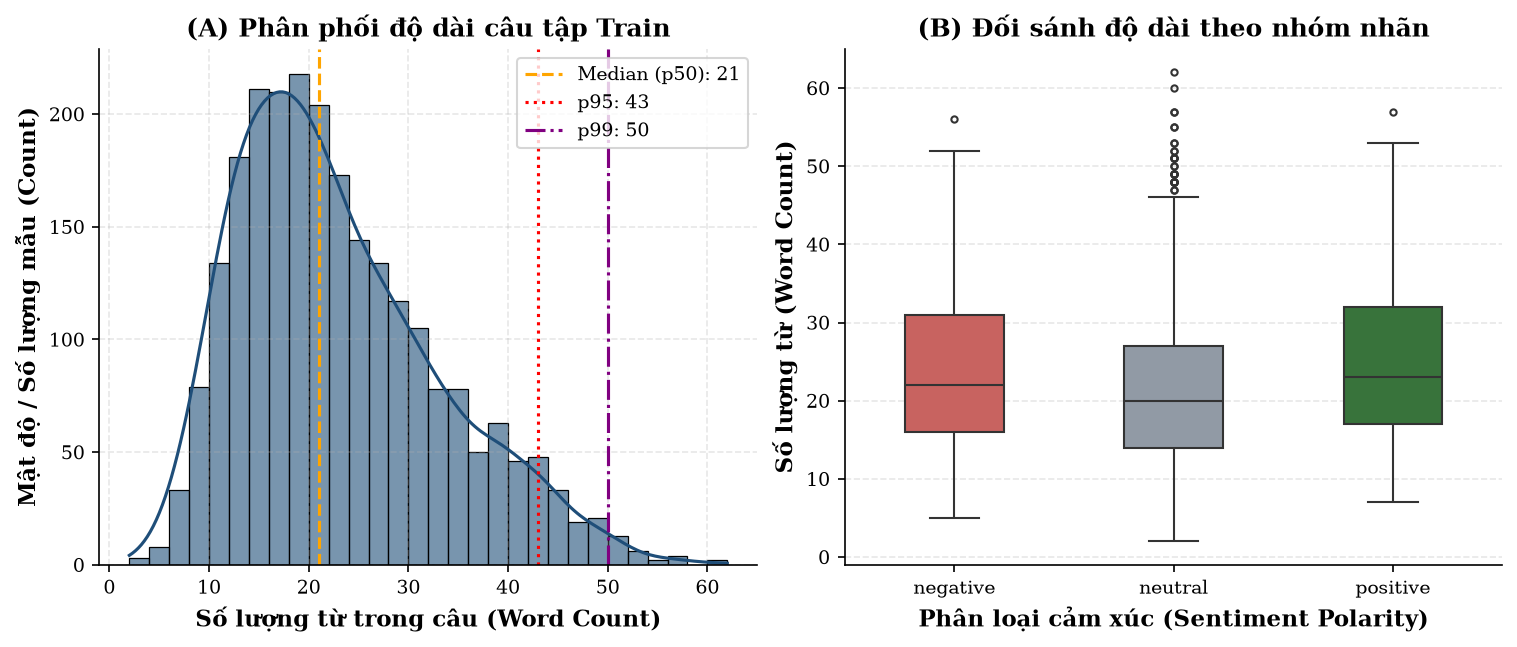

In [7]:
"""
cell 4: text length distribution & GPU memory optimization 
- Mục tiêu:
    1. tính toán độ dài văn bản (word_count) và char_count trên từng sample
    2. thống kê phân vị percentile 50, 75, 90, 95, 99, MAX %. 
    3. kiểm tra thiên lecchj độ dài (Length Bias check): so sánh xem câu nega, pos hay neutral có bị lẹch mạnh không?
    4. xem thử xem nên dùng config như nào cho máy local hiện tại (RTX 3050) 
    5. vẽ biểu dồ 2 khung, Gồm Histogram/KDE phân bố độ dài và Boxplot so sánh 3 nhãn cảm xúc, lưu ra reports/figures/sentence_length_distribution.pdf.
- Input: cột 'sentence' và 'label_name' của 'df_train'
- output: 
    - bảng thống kê phân vị 
    - quyết định max_seq_length 
    - biểu đồ 2 khung lưu pdf/png
"""

#1. tính độ dài từ và độ dài char
df_train["char_length"] = df_train["sentence"].apply(len)
df_train["word_count"] = df_train["sentence"].apply(lambda s: len(s.split()))

#2. Percentiles
percentiles = [50, 75, 90, 95, 99, 100]
pct_values = np.percentile(df_train["word_count"], percentiles)

print("-- percentiles word count --")
for p, val in zip(percentiles, pct_values):
    label = "Max" if p == 100 else f"p{p}"
    print(f"- Phân vị {label:<4}: {int(val):>3} từ")
mean_len = df_train["word_count"].mean()
std_len = df_train["word_count"].std()
print(f"\n- Trung bình (Mean ± Std): {mean_len:.1f} ± {std_len:.1f} từ")

# 3. Kiểm định thiên lệch độ dài theo nhãn cảm xúc
print(f"\n=== 2. ĐỘ DÀI TRUNG BÌNH THEO TỪNG NHÃN (LENGTH BIAS CHECK) ===")
len_by_class = df_train.groupby("label_name")["word_count"].agg(["count", "mean", "median", "max"])
print(len_by_class.round(1))

# 4. Đề xuất siêu tham số max_seq_length cho FinBERT
recommended_seq_len = 64 if pct_values[4] <= 60 else 128
print(f"\n=> KẾT LUẬN TỐI ƯU HÓA GPU (RTX 3050 VRAM):")
print(f"   99% số câu trong tập dữ liệu có độ dài <= {int(pct_values[4])} từ.")
print(f"   Khuyến nghị đặt `max_seq_length = {recommended_seq_len}` khi fine-tune FinBERT.")
print(f"   (Tiết kiệm ~75% bộ nhớ GPU so với cấu hình mặc định 512 tokens, tránh lỗi CUDA OOM).")

# 5. Trực quan hóa 2 panel chuẩn xuất bản (KDE Distribution + Boxplot)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.2), layout="constrained")
# Panel A: Phân phối tổng thể kèm các mốc phân vị
sns.histplot(
    df_train["word_count"],
    kde=True,
    ax=ax1,
    color="#1F4E79",
    bins=30,
    edgecolor="black",
    linewidth=0.6,
    alpha=0.6
)
ax1.axvline(pct_values[0], color="orange", linestyle="--", linewidth=1.5, label=f"Median (p50): {int(pct_values[0])}")
ax1.axvline(pct_values[3], color="red", linestyle=":", linewidth=1.5, label=f"p95: {int(pct_values[3])}")
ax1.axvline(pct_values[4], color="purple", linestyle="-.", linewidth=1.5, label=f"p99: {int(pct_values[4])}")
ax1.set_xlabel("Số lượng từ trong câu (Word Count)", fontweight="bold")
ax1.set_ylabel("Mật độ / Số lượng mẫu (Count)", fontweight="bold")
ax1.set_title("(A) Phân phối độ dài câu tập Train", fontweight="bold")
ax1.legend(loc="upper right")
# Panel B: Boxplot đối sánh độ dài giữa 3 nhãn cảm xúc
sns.boxplot(
    data=df_train,
    x="label_name",
    y="word_count",
    order=["negative", "neutral", "positive"],
    palette=PALETTE,
    ax=ax2,
    width=0.45,
    fliersize=3
)
ax2.set_xlabel("Phân loại cảm xúc (Sentiment Polarity)", fontweight="bold")
ax2.set_ylabel("Số lượng từ (Word Count)", fontweight="bold")
ax2.set_title("(B) Đối sánh độ dài theo nhóm nhãn", fontweight="bold")
# Lưu biểu đồ
pdf_path = FIGURES_DIR / "sentence_length_distribution.pdf"
png_path = FIGURES_DIR / "sentence_length_distribution.png"
fig.savefig(pdf_path, format="pdf")
fig.savefig(png_path, format="png")
print(f"\n[✓] Đã xuất biểu đồ học thuật tại:")
print(f"    + PDF: {pdf_path}")
print(f"    + PNG: {png_path}")
plt.show()